# Misclassification detection under distribution shift

A classifier will be wrong some of the time. A **misclassification detector**, or *safety
cage*, gives each prediction a score for how likely it is to be wrong; above a threshold
the prediction is **flagged** for review. This notebook fits four
[safetycage](https://github.com/SINTEF/safetycage) detectors to one CNN, tunes them on data
from the same slide collection the model was trained on, and checks how well they still
work on tiles from **new patients**: a separate slide collection the model has never seen.

| Cage | Scores a prediction from |
|---|---|
| **MSP** (Maximum Softmax Probability) | the model's confidence in its predicted class |
| **DOCTOR** | the whole vector of class probabilities |
| **RED** | a Gaussian process on input + probabilities, learning where confidence is off |
| **SPARDACUS** | a named layer's activations, compared with those of right and wrong predictions |
| **RandomBaseline** | nothing about the input: a random score, weighted by how often the predicted class is wrong (the baseline) |

Setup: `uv sync --extra tutorial` (Python ≥ 3.13). Runs in about three minutes on a laptop CPU, plus a one-off 206 MB download.

In [1]:
import os
import urllib.request
import warnings
from importlib.metadata import version
from pathlib import Path

os.environ["TQDM_DISABLE"] = "1"                            # safetycage progress bars
warnings.filterwarnings("ignore", category=FutureWarning)   # gpytorch, on import

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.datasets import get_data_home
from torch import nn

import themis_assess as ta

SEED = 42
rng = np.random.default_rng(SEED)
np.random.seed(SEED)        # SPARDACUS draws from NumPy's global generator
torch.manual_seed(SEED)
pd.set_option("display.precision", 3)
print("safetycage", version("safetycage"), "· themis-assess", ta.__version__, "· torch", torch.__version__)

safetycage 0.0.67 · themis-assess 0.12.0 · torch 2.14.1


## 1. Data

[PathMNIST](https://medmnist.com/) (Yang et al., 2023): 28×28 H&E-stained tiles of
colorectal tissue in 9 classes, from Kather et al. (2019).

| | Source | Slides |
|---|---|---|
| **home** (MedMNIST train + val) | NCT-CRC-HE-100K | 86 slides, NCT Biobank Heidelberg and UMM Mannheim; colour-normalised |
| **new patients** (MedMNIST test) | CRC-VAL-HE-7K | 50 other patients, NCT tissue bank |

The new-patient tiles come from the same tissue bank as part of the home data (NCT, Heidelberg),
but from 50 different patients: no patient appears in both sets.

The home tiles are split once: three parts for the model, three for the cages.

In [2]:
PATHMNIST_URL = "https://zenodo.org/records/10519652/files/pathmnist.npz?download=1"
CLASS_NAMES = ["adipose", "background", "debris", "lymphocytes", "mucus",
               "smooth muscle", "normal mucosa", "stroma", "tumour"]


def load_pathmnist():
    """PathMNIST at 28×28 (206 MB), downloaded once into scikit-learn's data folder."""
    path = Path(get_data_home()) / "medmnist" / "pathmnist.npz"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(PATHMNIST_URL, path)
    return np.load(path)


def flatten(images):
    """(n, 28, 28, 3) uint8 → (n, 2352) float32 in [0, 1]: one row per tile."""
    return images.reshape(len(images), -1).astype(np.float32) / 255


raw = load_pathmnist()
x_home = flatten(np.concatenate([raw["train_images"], raw["val_images"]]))
y_home = np.concatenate([raw["train_labels"], raw["val_labels"]]).ravel().astype(np.int64)
x_new, y_new = flatten(raw["test_images"]), raw["test_labels"].ravel().astype(np.int64)

SIZES = {"model · train": 30_000, "model · val": 3_000, "model · test": 3_000,
         "cage · train": 8_000, "cage · val": 4_000, "cage · test": 4_000}
order, start, split = rng.permutation(len(x_home)), 0, {}
for name, n in SIZES.items():
    split[name] = (x_home[order[start:start + n]], y_home[order[start:start + n]])
    start += n
split["new patients"] = (x_new, y_new)

pd.DataFrame({name: np.bincount(y, minlength=9) for name, (_, y) in split.items()},
             index=CLASS_NAMES).T.assign(total=lambda t: t.sum(axis=1))

,adipose,background,debris,lymphocytes,mucus,smooth muscle,normal mucosa,stroma,tumour,total
model · train,3126,3202,3534,3451,2602,4082,2595,3156,4252,30000
model · val,296,305,353,368,254,415,273,313,423,3000
model · test,311,347,349,330,256,403,265,305,434,3000
cage · train,807,837,948,873,753,1080,716,811,1175,8000
cage · val,413,401,440,449,353,556,401,405,582,4000
cage · test,405,428,437,478,389,541,354,390,578,4000
new patients,1338,847,339,634,1035,592,741,421,1233,7180


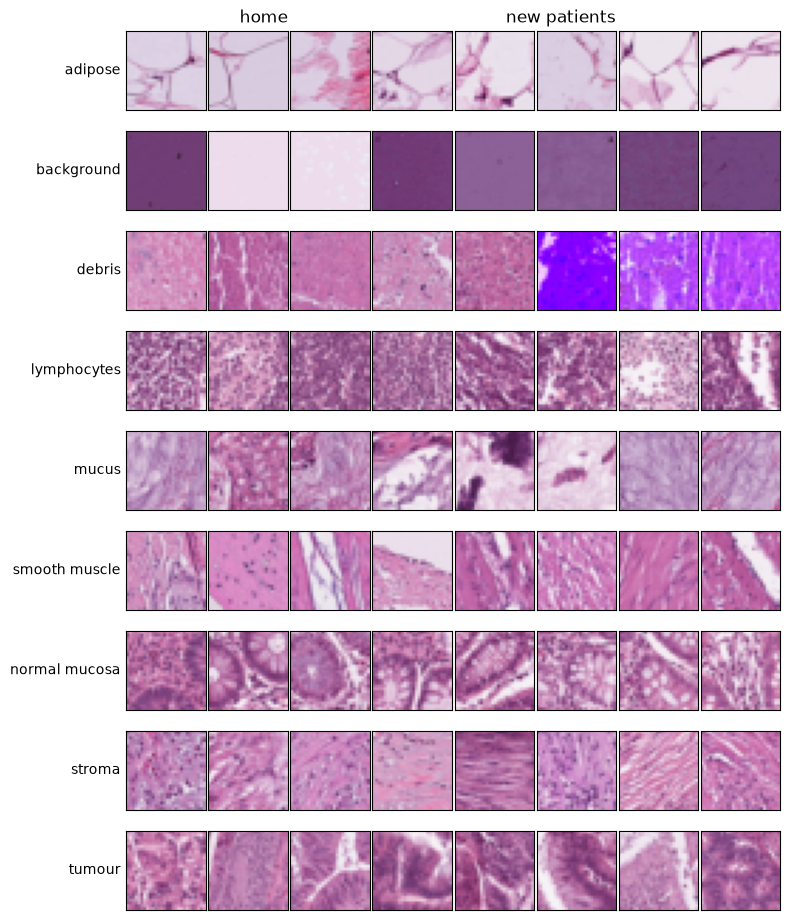

In [3]:
def show_tiles(ax_row, x, y, cls, n=4):
    for ax, i in zip(ax_row, rng.choice(np.flatnonzero(y == cls), n, replace=False)):
        ax.imshow(x[i].reshape(28, 28, 3))
        ax.set_xticks([]), ax.set_yticks([])


fig, axes = plt.subplots(9, 8, figsize=(8, 9.5))
for cls in range(9):
    show_tiles(axes[cls, :4], *split["cage · test"], cls)
    show_tiles(axes[cls, 4:], *split["new patients"], cls)
    axes[cls, 0].set_ylabel(CLASS_NAMES[cls], rotation=0, ha="right", va="center")
axes[0, 1].set_title("home", loc="right")
axes[0, 5].set_title("new patients", loc="right")
fig.tight_layout(h_pad=0.2, w_pad=0.2)
plt.show()

Same nine classes, but the new-patient tiles look different: some debris tiles are saturated violet, some smooth-muscle tiles salmon-coloured. The class mix differs too (table above). The model and the cages are never trained or tuned on new-patient tiles.

## 2. Model

A deliberately plain CNN: two convolution blocks and one hidden layer, trained with Adam.
Training stops once the loss on **model · val** has not improved for three epochs, and
the weights from the best epoch are kept.

The flat 2,352-value rows are reshaped to images inside `forward`, so every split stays a
plain array. The named `softmax` layer is not used for training; SPARDACUS reads it.

In [4]:
class CNN(nn.Module):
    def __init__(self, mean, std, n_classes=9):
        super().__init__()
        self.register_buffer("mean", torch.tensor(mean).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor(std).view(1, 3, 1, 1))
        self.conv1, self.act1, self.pool1 = nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        self.conv2, self.act2, self.pool2 = nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        self.fc, self.act3 = nn.Linear(32 * 7 * 7, 64), nn.ReLU()
        self.out = nn.Linear(64, n_classes)
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        x = (x.reshape(-1, 28, 28, 3).permute(0, 3, 1, 2) - self.mean) / self.std
        x = self.pool1(self.act1(self.conv1(x)))
        x = self.pool2(self.act2(self.conv2(x)))
        logits = self.out(self.act3(self.fc(x.flatten(1))))
        self.softmax(logits)        # unused here; computed so SPARDACUS can read it by name
        return logits


def train(x_train, y_train, x_val, y_val, max_epochs=30, patience=3, batch_size=64):
    pixels = x_train.reshape(-1, 28, 28, 3)
    model = CNN(pixels.mean((0, 1, 2)), pixels.std((0, 1, 2)))
    optimiser, loss_fn = torch.optim.Adam(model.parameters(), lr=1e-3), nn.CrossEntropyLoss()
    xt, yt, xv, yv = map(torch.tensor, (x_train, y_train, x_val, y_val))
    best_loss, best_epoch, best_state = np.inf, 0, None
    for epoch in range(max_epochs):
        model.train()
        for batch in torch.randperm(len(xt)).split(batch_size):
            optimiser.zero_grad()
            loss_fn(model(xt[batch]), yt[batch]).backward()
            optimiser.step()
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(xv), yv).item()
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        elif epoch - best_epoch >= patience:
            break
    model.load_state_dict(best_state)
    return model.eval(), best_epoch


cnn, best_epoch = train(*split["model · train"], *split["model · val"])


def probabilities(x):
    with torch.no_grad():
        return torch.softmax(cnn(torch.tensor(x)), dim=1).numpy()


def predict(x):
    return probabilities(x).argmax(axis=1)


x_test, y_test = split["model · test"]
print(f"stopped at epoch {best_epoch}; accuracy on model · test: {(predict(x_test) == y_test).mean():.3f}")

stopped at epoch 8; accuracy on model · test: 0.867


Accuracy with `themis-assess`, on home and on new-patient data. Balanced accuracy is the
mean of the per-class recalls; MCC (Matthews correlation coefficient) summarises the whole
confusion matrix, 1 = perfect and 0 = chance.

In [5]:
METRICS = ["accuracy", "balanced_accuracy", "matthews_corrcoef"]


def assess(predict_fn, x, y):
    handler = ta.CallableHandler(predict_fn, name="cnn")
    result = ta.AccuracyEvaluator(handler, metrics=METRICS, per_class=False).run(ta.ArrayAdapter(x), y)
    return {m: result[m] for m in METRICS}


pd.DataFrame({name: {**assess(predict, *split[name]), "mistakes": int((predict(split[name][0]) != split[name][1]).sum())}
              for name in ["model · test", "cage · test", "new patients"]}).T.convert_dtypes()

,accuracy,balanced_accuracy,matthews_corrcoef,mistakes
model · test,0.867,0.862,0.851,399
cage · test,0.867,0.864,0.851,531
new patients,0.775,0.716,0.745,1614


On home tiles the model is wrong 13% of the time; on new-patient tiles 22.5% of the time, and balanced accuracy falls from 0.86 to 0.72.

Confusion matrices: cell (*i*, *j*) counts tiles of true class *i* predicted as class *j*.
Off-diagonal cells are mistakes (red); correct predictions on the diagonal are in grey.

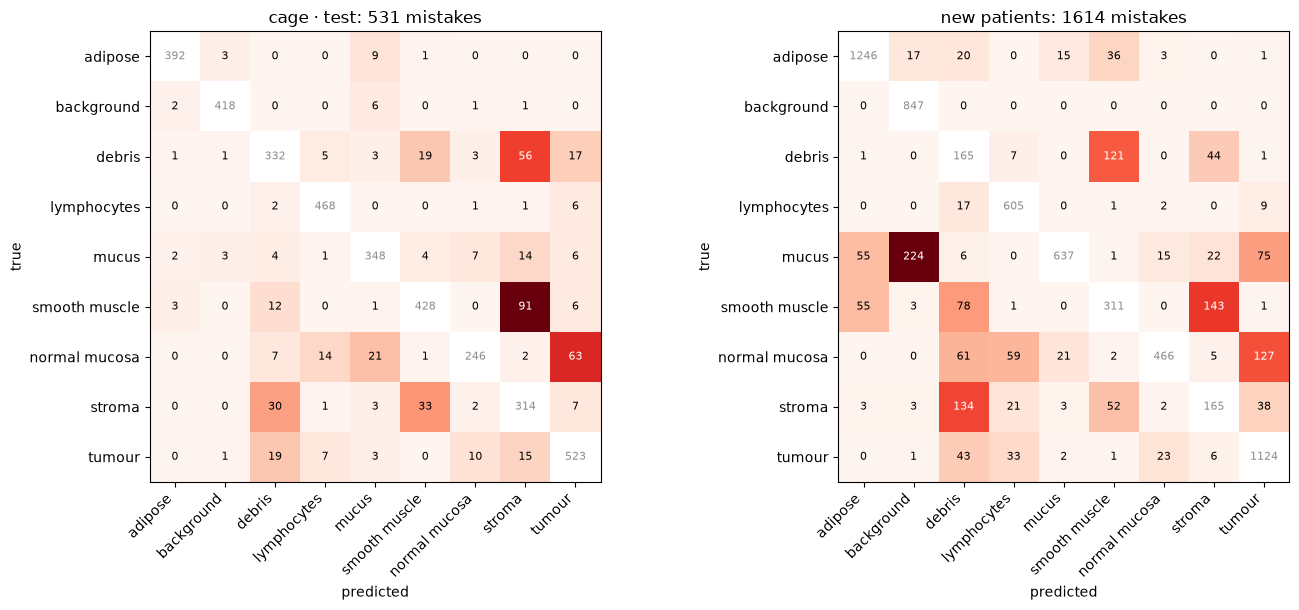

In [6]:
def confusion(x, y):
    handler = ta.CallableHandler(predict, name="cnn")
    return ta.AccuracyEvaluator(handler, metrics=["accuracy"]).run(ta.ArrayAdapter(x), y).confusion


TEST_SETS = ["cage · test", "new patients"]
confusions = {where: confusion(*split[where]) for where in TEST_SETS}

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
for ax, (where, cm) in zip(axes, confusions.items()):
    counts = np.asarray(cm.matrix)
    mistakes = np.where(np.eye(len(counts), dtype=bool), np.nan, counts)
    ax.imshow(mistakes, cmap="Reds")
    for i, j in np.ndindex(counts.shape):
        dark = i != j and counts[i, j] > np.nanmax(mistakes) / 2
        ax.text(j, i, counts[i, j], ha="center", va="center", fontsize=8,
                color="0.55" if i == j else "white" if dark else "black")
    names = [CLASS_NAMES[int(label)] for label in cm.labels]
    ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
    ax.set_yticks(range(len(names)), names)
    ax.set(title=f"{where}: {int(np.nansum(mistakes))} mistakes", xlabel="predicted", ylabel="true")
fig.tight_layout()
plt.show()

At home the largest confusions are between similar-looking tissues: smooth muscle → stroma (91), normal mucosa → tumour (63), debris → stroma (56). On new patients these pairs grow and new ones appear: mucus → background (224), stroma → debris (134), debris → smooth muscle (121). Stroma is classified correctly in only 165 of 421 new-patient tiles (39%).

The same mistakes as flows: true class on the left, predicted class on the right, link
width = number of tiles. Correct predictions are left out. Hover over a link for its count.

In [7]:
import plotly.graph_objects as go
import plotly.io as pio
from plotly.colors import qualitative

pio.renderers.default = "notebook_connected"
COLOURS = qualitative.Safe[:9]      # one colour per class, "rgb(r, g, b)"


def mistake_sankey(cm, x_domain):
    counts = np.asarray(cm.matrix)
    names = [CLASS_NAMES[int(label)] for label in cm.labels]
    n = len(names)
    true, pred = np.nonzero(~np.eye(n, dtype=bool) & (counts > 0))
    return go.Sankey(
        domain={"x": x_domain},
        node={"label": names + names, "color": COLOURS + COLOURS, "pad": 10},
        link={"source": true.tolist(), "target": (pred + n).tolist(), "value": counts[true, pred].tolist(),
              "color": [COLOURS[k].replace("rgb", "rgba").replace(")", ", 0.45)") for k in true]},
    )


domains = [[0, 0.46], [0.54, 1]]
fig = go.Figure([mistake_sankey(confusions[where], d) for where, d in zip(TEST_SETS, domains)])
fig.update_layout(
    height=560, margin={"t": 70, "l": 10, "r": 10, "b": 10},
    annotations=[{"text": f"{where}: true → predicted, {int(cm.matrix.sum() - np.trace(cm.matrix))} mistakes",
                  "x": sum(d) / 2, "y": 1.08, "xref": "paper", "yref": "paper", "showarrow": False}
                 for (where, cm), d in zip(confusions.items(), domains)],
)
fig.show()

## 3. Fit the cages

Every cage is fitted on **cage · train** and its threshold is tuned on **cage · val**, both
from home. The threshold maximises MCC (Matthews correlation coefficient) between *flagged*
and *wrong*. The cage data is separate from the model's training data, so it contains
mistakes at the model's normal rate.

In [8]:
from safetycage.datamodules.array_datamodule import ArrayDataModule
from safetycage.methods.doctor import DOCTOR
from safetycage.methods.msp import MSP
from safetycage.methods.random_baseline import RandomBaseline
from safetycage.methods.red import RED
from safetycage.methods.spardacus import SPARDACUS
from safetycage.modelmodules.torch_modelmodule import TorchModelModule
from safetycage.utils.metrics import MCC

module = TorchModelModule(cnn, selected_layers=["softmax"])
data = ArrayDataModule(*split["cage · train"], *split["cage · val"], *split["cage · test"])

cages = {
    "MSP": MSP(module, data),
    "DOCTOR": DOCTOR(module, data, method="sum"),
    "RED": RED(module, data, random_state=SEED),
    "SPARDACUS": SPARDACUS(module, data, s_statistic_source="incorrectly"),
    "RandomBaseline": RandomBaseline(module, data, random_state=SEED),
}
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for cage in cages.values():
        cage.fit()
        cage.fit_threshold(metric_fn=MCC)

## 4. Home vs new patients

For each cage and each test set:

- **AUROC**: probability that a wrong prediction scores as more suspicious than a right one (0.5 = chance, 1 = perfect). It doesn't depend on the threshold.
- **flagged**: share of tiles sent for review.
- **caught**: share of the model's mistakes among the flagged tiles.
- **precision**: share of flagged tiles that really were wrong.

In [9]:
def evaluate(cage, x, y):
    y_pred = predict(x)
    score = np.asarray(cage.predict(x, y_pred), dtype=float)
    flagged = np.asarray(cage.flag(score), dtype=bool)
    wrong = y_pred != y
    auroc = cage.auroc(y_true=wrong.astype(int), y_pred=score)
    return {"score": score, "flagged": flagged, "wrong": wrong, "y_pred": y_pred, "auroc": auroc}


with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    outcomes = {(where, name): evaluate(cage, *split[where]) for where in TEST_SETS for name, cage in cages.items()}

pd.DataFrame({
    key: {"AUROC": o["auroc"], "flagged": o["flagged"].mean(),
          "caught": (o["flagged"] & o["wrong"]).sum() / o["wrong"].sum(),
          "precision": (o["flagged"] & o["wrong"]).sum() / o["flagged"].sum()}
    for key, o in outcomes.items()
}).T

AUROC  flagged  caught  precision
cage · test  MSP             0.881    0.312   0.842      0.358
             DOCTOR          0.880    0.317   0.855      0.358
             RED             0.885    0.292   0.844      0.384
             SPARDACUS       0.862    0.287   0.766      0.354
             RandomBaseline  0.657    0.676   0.878      0.172
new patients MSP             0.786    0.353   0.687      0.437
             DOCTOR          0.784    0.359   0.693      0.434
             RED             0.796    0.311   0.673      0.486
             SPARDACUS       0.777    0.349   0.672      0.433
             RandomBaseline  0.615    0.579   0.716      0.278

- **Home:** the four cages reach AUROC 0.86–0.89. The tuned threshold flags under a third of the tiles and catches 77–86% of the mistakes.
- **New patients:** AUROC falls to 0.78–0.80. The same thresholds flag *more* tiles and catch *fewer* mistakes (67–69%).
- **RandomBaseline:** AUROC 0.66 and 0.62, above 0.5 only because it knows which predicted classes are error-prone. Its MCC-tuned threshold flags 58–68% of the tiles.
- The four cages are close. RED is marginally best on both sets; MSP, which needs no fitting, is nearly as good.

### Review budget

Sort the tiles from most to least suspicious and review the top *k* %. The curve shows the
share of mistakes caught for every *k*; the dot is the tuned threshold. RandomBaseline is
dotted.

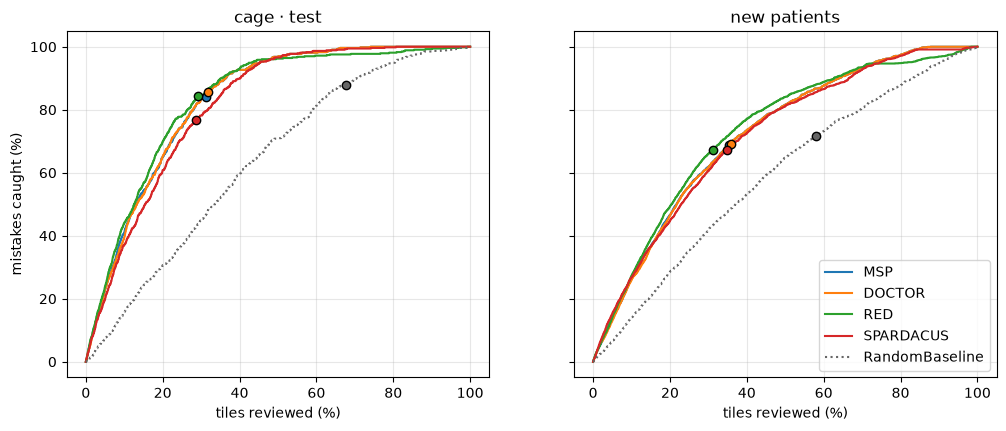

In [10]:
def suspicion_order(cage, score):
    # Tile indices, most suspicious first. MSP, RED and RandomBaseline flag low scores (leq=True).
    flags_low = getattr(cage, "leq", None) is True
    return np.argsort(score if flags_low else -score, kind="stable")


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, where in zip(axes, TEST_SETS):
    for name, cage in cages.items():
        o = outcomes[(where, name)]
        caught = np.concatenate([[0], np.cumsum(o["wrong"][suspicion_order(cage, o["score"])])]) / o["wrong"].sum()
        style = {"c": "0.4", "ls": ":"} if name == "RandomBaseline" else {}
        line, = ax.plot(np.linspace(0, 100, len(caught)), 100 * caught, label=name, **style)
        ax.scatter(100 * o["flagged"].mean(), 100 * (o["flagged"] & o["wrong"]).sum() / o["wrong"].sum(),
                   color=line.get_color(), edgecolor="black", zorder=3)
    ax.set(title=where, xlabel="tiles reviewed (%)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("mistakes caught (%)")
axes[1].legend(loc="lower right")
plt.show()

Every cage stays above RandomBaseline at every budget, but the gap narrows on new patients. Reviewing 30% of the tiles catches about 85% of the mistakes at home (RandomBaseline: about 45%) and about 65% on new patients (RandomBaseline: about 40%).

## 5. What gets flagged, and what slips through

New-patient tiles, scored by RED. Top row: the most suspicious tiles. Bottom row: the
mistakes RED found *least* suspicious, i.e. the model was confidently wrong. Titles are
*true → predicted*.

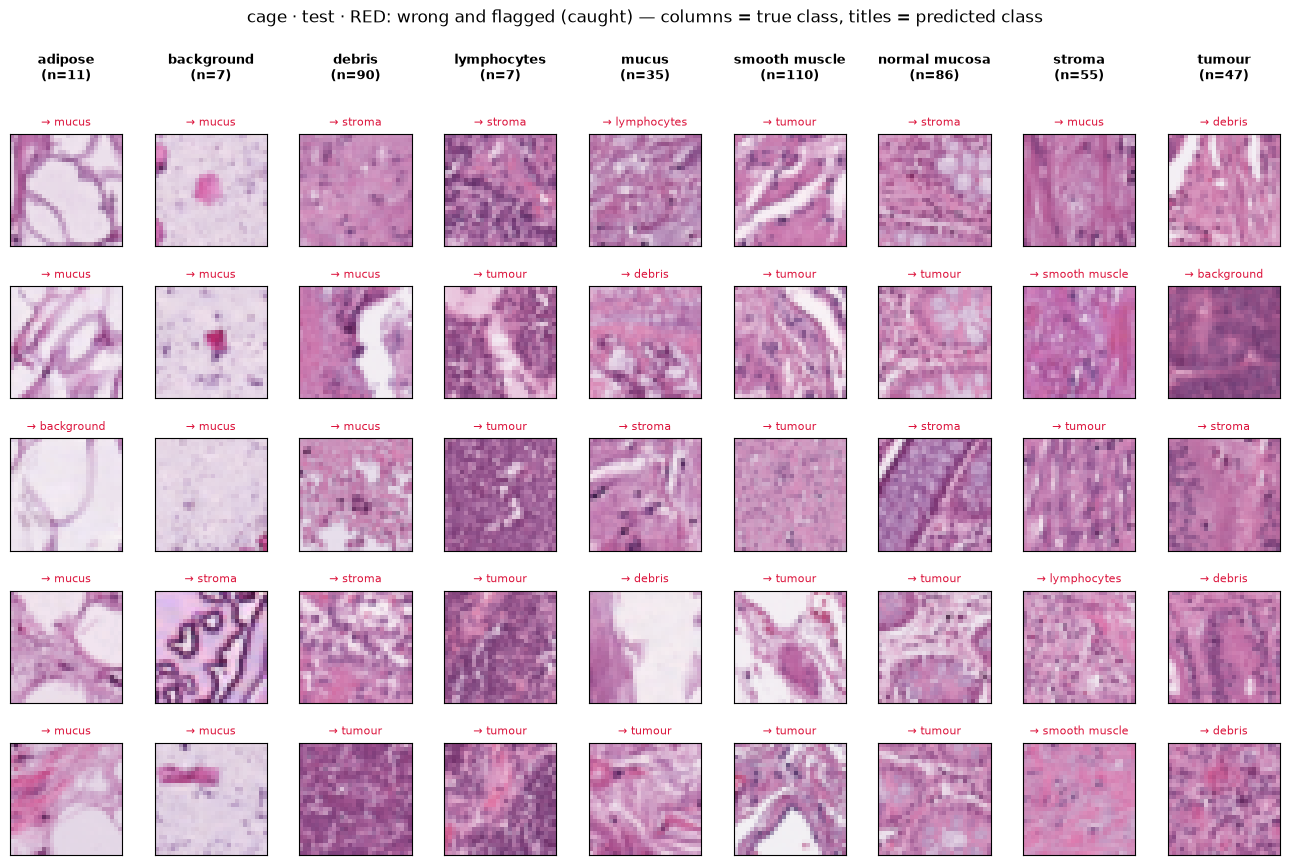

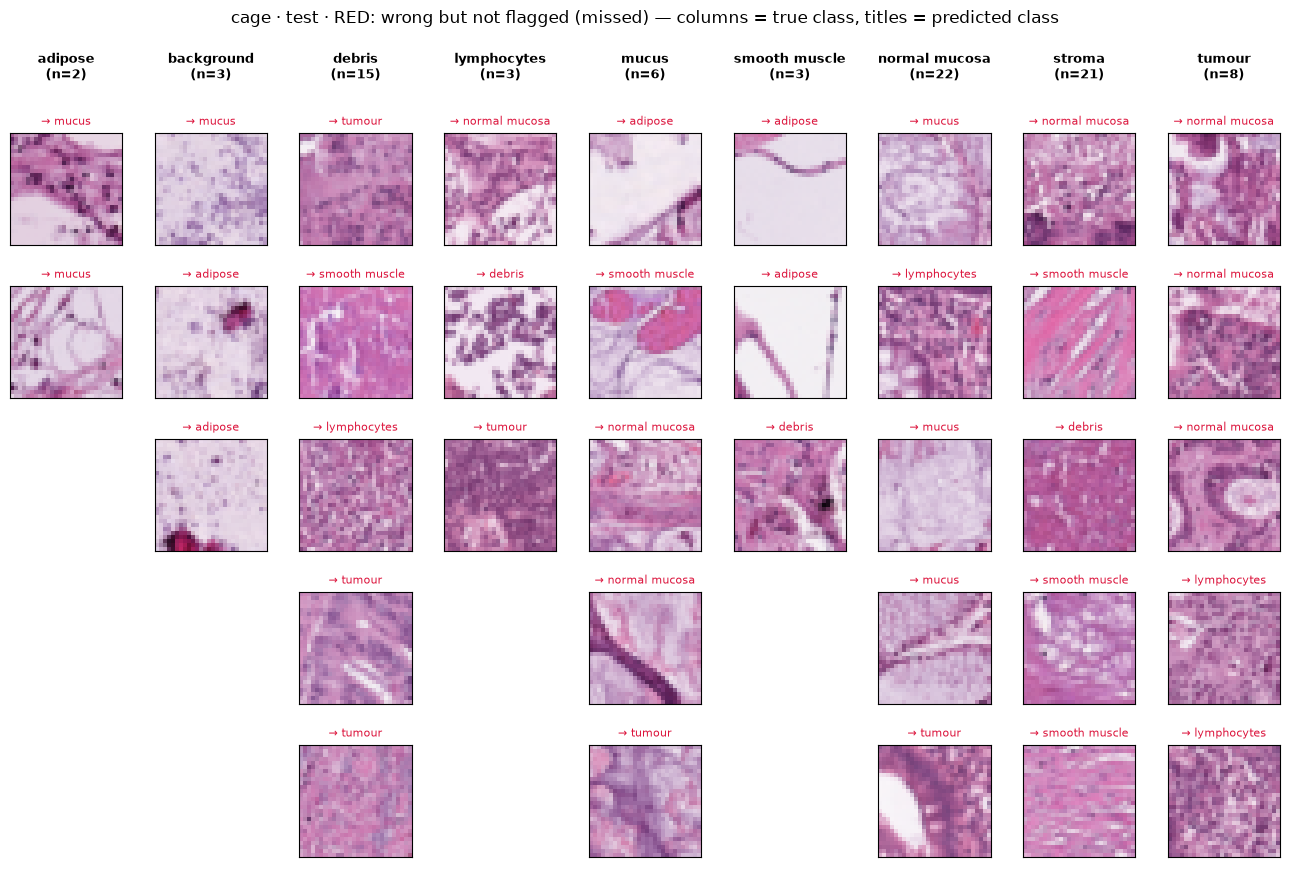

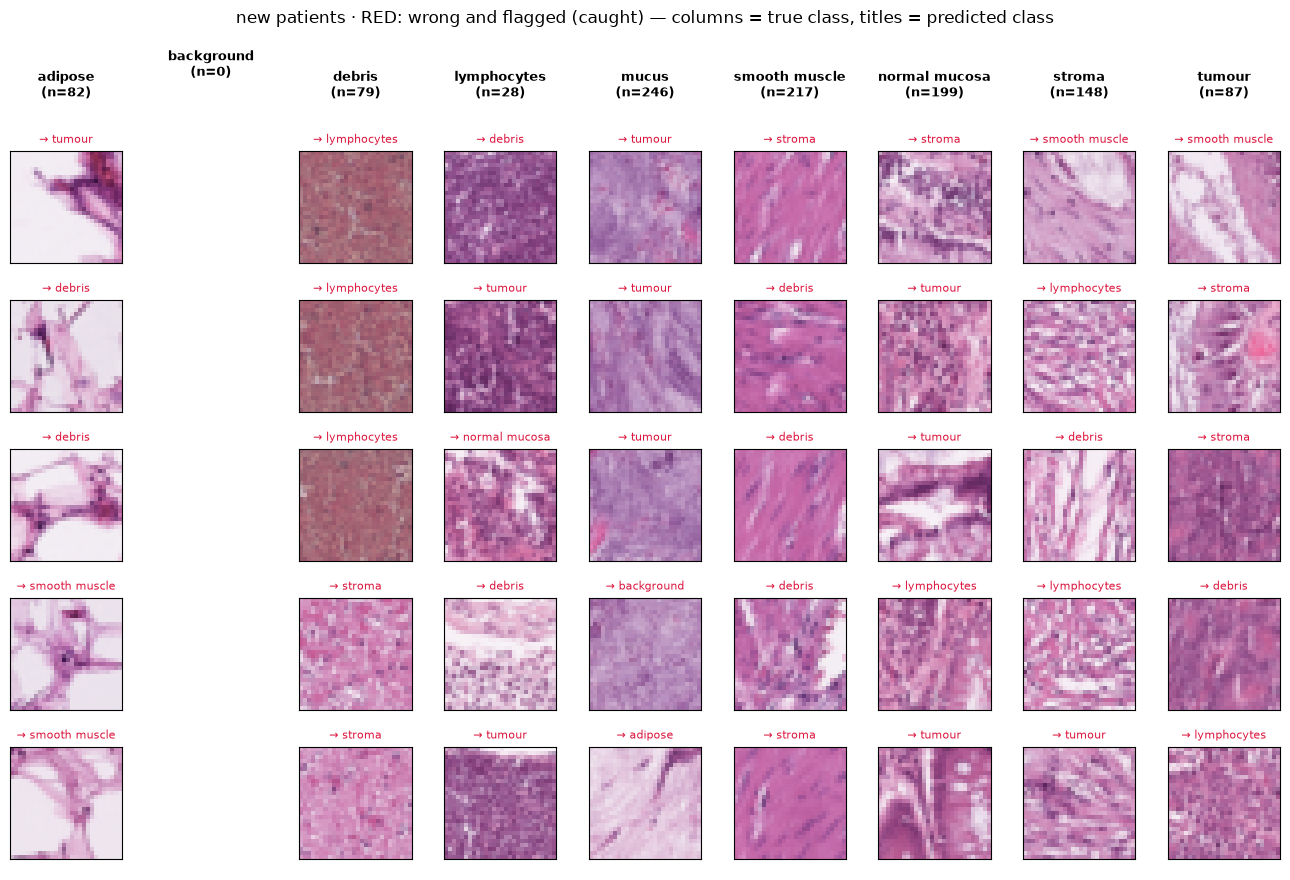

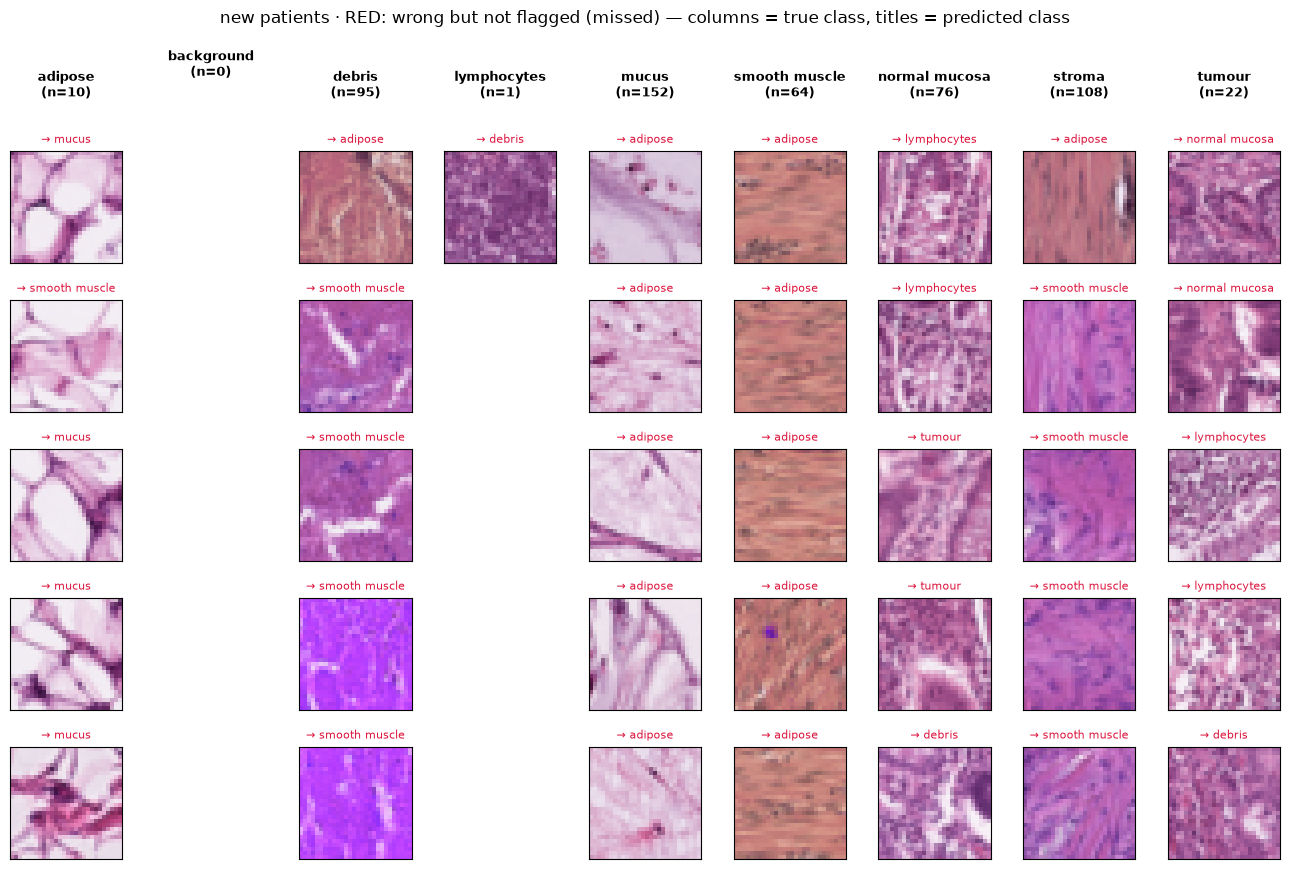

In [103]:
name, N_PER_CLASS = "RED", 5


def mistake_grid(where, kind):
    """Columns = true class; up to N_PER_CLASS wrong tiles per class, titled with the predicted class.
    kind="caught": wrong and flagged, most suspicious first.
    kind="missed": wrong but not flagged, least suspicious first."""
    o, (x, y) = outcomes[(where, name)], split[where]
    ranked = suspicion_order(cages[name], o["score"])
    if kind == "caught":
        keep, order = o["wrong"] & o["flagged"], ranked
    else:
        keep, order = o["wrong"] & ~o["flagged"], ranked[::-1]
    order = order[keep[order]]

    fig, axes = plt.subplots(N_PER_CLASS, 9, figsize=(13, 1.55 * N_PER_CLASS + 1), squeeze=False)
    for cls in range(9):
        in_class = order[y[order] == cls]
        idx = in_class[:N_PER_CLASS]
        for row in range(N_PER_CLASS):
            ax = axes[row, cls]
            ax.set_xticks([]), ax.set_yticks([])
            if row < len(idx):
                i = idx[row]
                ax.imshow(x[i].reshape(28, 28, 3))
                ax.set_title(f"→ {CLASS_NAMES[o['y_pred'][i]]}", fontsize=8, color="crimson")
            else:
                ax.axis("off")
        axes[0, cls].annotate(f"{CLASS_NAMES[cls]}\n(n={len(in_class)})", xy=(0.5, 1.45),
                              xycoords="axes fraction", ha="center", va="bottom",
                              fontsize=9, fontweight="bold")
    label = "wrong and flagged (caught)" if kind == "caught" else "wrong but not flagged (missed)"
    fig.suptitle(f"{where} · {name}: {label} — columns = true class, titles = predicted class", y=1.0)
    fig.tight_layout()
    plt.show()


for where in TEST_SETS:
    for kind in ["caught", "missed"]:
        mistake_grid(where, kind)


The missed mistakes are smooth-muscle tiles in a salmon-coloured stain unlike the home tiles in section 1. The model calls them adipose with high confidence, so the cage ranks them as safe. Confident mistakes on shifted inputs are the errors these detectors miss.

## 6. Model plus reviewer

Every flagged tile goes to a pathologist, simulated here by the true label (an optimistic
assumption). Unflagged tiles keep the model's prediction.

In [12]:
review = {}
for where in TEST_SETS:
    x, y = split[where]
    review[(where, "model alone")] = {**assess(predict, x, y), "reviewed": 0.0}
    for name in cages:
        o = outcomes[(where, name)]
        reviewed = np.where(o["flagged"], y, o["y_pred"])
        review[(where, f"+ review ({name})")] = {**assess(lambda _: reviewed, x, y), "reviewed": o["flagged"].mean()}
pd.DataFrame(review).T

accuracy  balanced_accuracy  \
cage · test  model alone                   0.867              0.864   
             + review (MSP)                0.979              0.977   
             + review (DOCTOR)             0.981              0.979   
             + review (RED)                0.979              0.977   
             + review (SPARDACUS)          0.969              0.968   
             + review (RandomBaseline)     0.984              0.983   
new patients model alone                   0.775              0.716   
             + review (MSP)                0.930              0.903   
             + review (DOCTOR)             0.931              0.904   
             + review (RED)                0.926              0.898   
             + review (SPARDACUS)          0.926              0.893   
             + review (RandomBaseline)     0.936              0.934   

                                        matthews_corrcoef  reviewed  
cage · test  model alone                            0.851     0.000  
             + review (MSP)                         0.976     0.312  
             + review (DOCTOR)                      0.978     0.317  
             + review (RED)                         0.977     0.292  
             + review (SPARDACUS)                   0.965     0.287  
             + review (RandomBaseline)              0.982     0.676  
new patients model alone                            0.745     0.000  
             + review (MSP)                         0.920     0.353  
             + review (DOCTOR)                      0.921     0.359  
             + review (RED)                         0.916     0.311  
             + review (SPARDACUS)                   0.915     0.349  
             + review (RandomBaseline)              0.928     0.579

Reviewing the flagged 29–36% of tiles raises accuracy from 0.87 to 0.97–0.98 at home, but on new patients only from 0.78 to about 0.93. RandomBaseline reaches similar accuracy only by sending 58–68% of the tiles to review.

## Summary

**Gain per review**: each metric's improvement over the model alone, divided by the share of
tiles reviewed. For accuracy this equals the share of reviews that fix a mistake.

**RandomBaseline** is safetycage's control, fitted and tuned like the other cages. It ignores
the input. On cage · train it measures, for each class, how often the model is wrong when it
predicts that class. Each tile then gets a random number divided by its predicted class's
error rate, so tiles predicted as error-prone classes are flagged more often; within a class,
flagging is pure chance. A cage that does not beat it adds nothing beyond knowing which
classes the model tends to get wrong.

*× RandomBaseline* is a cage's gain per review divided by RandomBaseline's on the same data.

In [13]:
gain = {}
for where in TEST_SETS:
    alone = review[(where, "model alone")]
    for name in cages:
        r = review[(where, f"+ review ({name})")]
        gain[(where, name)] = {"reviewed": r["reviewed"],
                               "Δ accuracy": r["accuracy"] - alone["accuracy"],
                               "Δ MCC": r["matthews_corrcoef"] - alone["matthews_corrcoef"]}
gain = pd.DataFrame(gain).T
for metric in ["accuracy", "MCC"]:
    per_review = gain[f"Δ {metric}"] / gain["reviewed"]
    baseline = per_review.xs("RandomBaseline", level=1)
    gain[f"Δ {metric} / reviewed"] = per_review
    gain[f"{metric} × RandomBaseline"] = per_review / baseline.reindex(gain.index.get_level_values(0)).to_numpy()
gain

reviewed  Δ accuracy  Δ MCC  \
cage · test  MSP                0.312       0.112  0.125   
             DOCTOR             0.317       0.114  0.127   
             RED                0.292       0.112  0.126   
             SPARDACUS          0.287       0.102  0.114   
             RandomBaseline     0.676       0.117  0.131   
new patients MSP                0.353       0.154  0.175   
             DOCTOR             0.359       0.156  0.176   
             RED                0.311       0.151  0.171   
             SPARDACUS          0.349       0.151  0.171   
             RandomBaseline     0.579       0.161  0.183   

                             Δ accuracy / reviewed  accuracy × RandomBaseline  \
cage · test  MSP                             0.358                      2.079   
             DOCTOR                          0.358                      2.078   
             RED                             0.384                      2.226   
             SPARDACUS                       0.354                      2.054   
             RandomBaseline                  0.172                      1.000   
new patients MSP                             0.437                      1.575   
             DOCTOR                          0.434                      1.563   
             RED                             0.486                      1.750   
             SPARDACUS                       0.433                      1.560   
             RandomBaseline                  0.278                      1.000   

                             Δ MCC / reviewed  MCC × RandomBaseline  
cage · test  MSP                        0.402                 2.078  
             DOCTOR                     0.402                 2.078  
             RED                        0.431                 2.226  
             SPARDACUS                  0.397                 2.053  
             RandomBaseline             0.193                 1.000  
new patients MSP                        0.496                 1.567  
             DOCTOR                     0.492                 1.555  
             RED                        0.551                 1.742  
             SPARDACUS                  0.490                 1.549  
             RandomBaseline             0.316                 1.000

- **Home:** a review fixes a mistake 35–38% of the time, against 17% for RandomBaseline: the cages are 2.1–2.2× better per review, for accuracy and MCC alike.
- **New patients:** reviews fix mistakes more often (43–49%) because the model makes more of them, but so does RandomBaseline (28%), so the cages are only 1.6–1.75× better. The home-tuned thresholds flag more tiles and catch fewer mistakes, and AUROC drops from about 0.88 to 0.79.
- The mistakes that get through are confident ones on shifted inputs.
- RED gives the most per review on both sets; MSP, which needs no fitting, is close behind. Validate a cage, and its threshold, on data like the data it will be used on.